# UTS Graf Sains Data

zulma nayla ifaada


In [4]:
!uv pip install neo4j pandas numpy scipy scikit-learn networkx matplotlib tqdm

Using Python 3.12.10 environment at: d:\Naya Geming\antech\myenv
Resolved 24 packages in 2.76s
 Downloaded fonttools
 Downloaded networkx
 Downloaded pillow
 Downloaded matplotlib
 Downloaded scikit-learn
 Downloaded numpy
 Downloaded pandas
 Downloaded scipy
Prepared 19 packages in 41.00s
         If the cache and target directories are on different filesystems, hardlinking may not be supported.
         If this is intentional, set `export UV_LINK_MODE=copy` or use `--link-mode=copy` to suppress this warning.
Installed 20 packages in 24.70s
 + cloudpickle==3.1.2
 + contourpy==1.4.0
 + cycler==0.12.1
 + fonttools==4.67.0
 + joblib==1.6.0
 + kiwisolver==1.5.1
 + matplotlib==3.11.2
 + narwhals==2.27.1
 + neo4j==6.4.1
 + networkx==3.7
 + numpy==2.5.4
 + pandas==3.0.6
 + pillow==13.0.0
 + pyparsing==3.3.3
 + pytz==2026.5
 + scikit-learn==1.9.1
 + scipy==1.18.1
 + threadpoolctl==3.7.0
 + tqdm==4.70.1
 + tzdata==2026.5


In [23]:
import os, math
import numpy as np
import pandas as pd
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.preprocessing import normalize
from tqdm.auto import tqdm
from neo4j import GraphDatabase

SEED = 42
rng = np.random.default_rng(SEED)

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "Nayagaming")      
DATABASE = "neo4j"

DATA_DIR = "data"
EVENTS_CSV = os.path.join(DATA_DIR, "events.csv")

P1_START, P1_END = pd.Timestamp("2015-05-12"), pd.Timestamp("2015-07-12")   # s.d. 11-07-2015
P2_START, P2_END = pd.Timestamp("2015-07-12"), pd.Timestamp("2015-09-13")   # s.d. 12-09-2015

BATCH_SIZE = 5000
RESET_DB = False    

REL_BY_EVENT = {"view": "VIEWED", "addtocart": "ADDED_TO_CART", "transaction": "BOUGHT"}
REL_WEIGHT = {"VIEWED": 1.0, "ADDED_TO_CART": 3.0, "BOUGHT": 5.0}
REL = "|".join(REL_WEIGHT)   # VIEWED|ADDED_TO_CART|BOUGHT

In [24]:
driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()

def run_read(query, **params):
    with driver.session(database=DATABASE) as s:
        return s.run(query, **params).data()

def run_write(query, **params):
    with driver.session(database=DATABASE) as s:
        s.run(query, **params).consume()

## 2.1 Wrangling dan EDA

### No. 1 dan 2: Penentuan periode, filter `timestamp`, dan simpan ke `.csv`

In [25]:
import os

DATA_DIR = "D:\\Naya Geming\\antech\\UTSS\\data"
os.makedirs(DATA_DIR, exist_ok=True)

print("Folder data tersedia:", os.path.abspath(DATA_DIR))

Folder data tersedia: D:\Naya Geming\antech\UTSS\data


In [26]:
events = pd.read_csv(r"C:\Users\ASUS\retailrocket\events.csv")
events["datetime"] = pd.to_datetime(events["timestamp"], unit="ms")   # UTC
print("Seluruh data :", events.shape, "|", events["datetime"].min(), "->", events["datetime"].max())

p1 = events[(events["datetime"] >= P1_START) & (events["datetime"] < P1_END)].copy()
p2 = events[(events["datetime"] >= P2_START) & (events["datetime"] < P2_END)].copy()
assert p1["datetime"].max() < p2["datetime"].min(), "P1 dan P2 beririsan"

ringkasan = pd.DataFrame({
    "baris": [len(p1), len(p2)],
    "visitor unik": [p1["visitorid"].nunique(), p2["visitorid"].nunique()],
    "item unik": [p1["itemid"].nunique(), p2["itemid"].nunique()],
    "mulai": [p1["datetime"].min(), p2["datetime"].min()],
    "akhir": [p1["datetime"].max(), p2["datetime"].max()],
}, index=["P1 (training)", "P2 (testing)"])
display(ringkasan)

irisan = p1["visitorid"].drop_duplicates().isin(
    p2["visitorid"].drop_duplicates()
).sum()

print(f"Visitor P2 yang juga ada di P1: {irisan} dari {p2['visitorid'].nunique()}")
p1.assign(fold="P1").to_csv(os.path.join(DATA_DIR, "events_p1.csv"), index=False)
p2.assign(fold="P2").to_csv(os.path.join(DATA_DIR, "events_p2.csv"), index=False)
pd.concat([p1.assign(fold="P1"), p2.assign(fold="P2")]).to_csv(
    os.path.join(DATA_DIR, "events_filtered.csv"), index=False)

Seluruh data : (2756101, 6) | 2015-05-03 03:00:04.384000 -> 2015-09-18 02:59:47.788000


,baris,visitor unik,item unik,mulai,akhir
P1 (training),1272928,645108,168629,2015-05-12 00:00:03.576,2015-07-11 23:59:57.604
P2 (testing),1238187,674515,167948,2015-07-12 00:00:02.350,2015-09-12 23:59:47.942


Visitor P2 yang juga ada di P1: 30970 dari 674515


### Impor data P1 ke Neo4j (mekanisme batch)

Satu batch dipisah per jenis `event` di Python, sehingga setiap query Cypher hanya membuat satu jenis relasi.
Pendekatan ini setara dengan `CALL { ... UNION ALL ... }` pada kode sumber, tetapi lebih ringan dan tidak bergantung pada versi Neo4j.

In [37]:
def create_constraints():
    run_write("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    run_write("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

def import_query(event):
    extra = ", transactionId: row.transactionid" if event == "transaction" else ""
    return f"""
    UNWIND $batch AS row
    MERGE (v:Visitor {{visitorId: row.visitorid}})
    MERGE (i:Item {{itemId: row.itemid}})
    CREATE (v)-[:{REL_BY_EVENT[event]} {{timestamp: row.timestamp{extra}}}]->(i)
    """

n_existing = run_read("MATCH (n) RETURN count(n) AS n")[0]["n"]
if RESET_DB:
    run_write("MATCH (n) CALL { WITH n DETACH DELETE n } IN TRANSACTIONS OF 10000 ROWS")
    n_existing = 0

if n_existing > 0:
    print(f"Database sudah berisi {n_existing} simpul, impor dilewati (set RESET_DB=True untuk impor ulang).")
else:
    create_constraints()
    p1_path = os.path.join(DATA_DIR, "events_p1.csv")
    total_rows = len(p1)
    total_chunks = math.ceil(total_rows / BATCH_SIZE)
    chunks = pd.read_csv(p1_path, chunksize=BATCH_SIZE,
                         usecols=["timestamp", "visitorid", "event", "itemid", "transactionid"])
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor batch"):
        for ev in REL_BY_EVENT:
            sub = chunk[chunk["event"] == ev]
            if sub.empty:
                continue
            cols = ["timestamp", "visitorid", "itemid"]
            if ev == "transaction":
                sub = sub.assign(transactionid=sub["transactionid"].astype("int64"))
                cols.append("transactionid")
            records = sub[cols].astype("int64").astype(object).to_dict(orient="records")
            run_write(import_query(ev), batch=records)
    print("Proses impor berhasil.")

Mengimpor batch: 100%|██████████| 255/255 [02:16<00:00,  1.87it/s]

Proses impor berhasil.


In [38]:
print(run_read("MATCH (n) RETURN labels(n)[0] AS tipe, count(n) AS n"))

[{'tipe': 'Visitor', 'n': 645108}, {'tipe': 'Item', 'n': 168629}]


### No. 3: Komposisi subgraph

Dua query Cypher dipakai:

1. `MATCH (n) RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah`
   memindai seluruh simpul, mengambil label pertama tiap simpul, lalu `count` menghitung jumlah simpul per label (pengelompokan terjadi otomatis oleh `RETURN`).
2. `MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(r) AS jumlah`
   memindai seluruh relasi dan menghitung jumlahnya per tipe (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`).

In [29]:
node_counts = pd.DataFrame(run_read(
    "MATCH (n) RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah ORDER BY jumlah DESC"))
rel_counts = pd.DataFrame(run_read(
    "MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(r) AS jumlah ORDER BY jumlah DESC"))
display(node_counts)
display(rel_counts)

,jenis_simpul,jumlah
0,Visitor,1407580
1,Item,235061
2,Person,6


,jenis_relasi,jumlah
0,VIEWED,2664312
1,ADDED_TO_CART,69332
2,BOUGHT,22457
3,KNOWS,4


### No. 4 dan 5: Vector Space Modelling (VSM)

Matriks interaksi `X` dibentuk dari graf. Bobot sel = jumlah relasi dikali bobot jenisnya (`VIEWED`=1, `ADDED_TO_CART`=3, `BOUGHT`=5).

- **VSM User**: tiap baris adalah satu `Visitor`, dimensi vektor = jumlah `Item` (shape `n_user x n_item`).
- **VSM Item**: tiap baris adalah satu `Item`, dimensi vektor = jumlah `Visitor` (shape `n_item x n_user`, yaitu transpos).

In [ ]:
print(run_read("MATCH (n) RETURN labels(n)[0] AS tipe, count(n) AS n"))

In [39]:
rows = run_read(f"""
MATCH (v:Visitor)-[r:{REL}]->(i:Item)
RETURN v.visitorId AS visitor, i.itemId AS item, type(r) AS rel, count(r) AS n
""")
df = pd.DataFrame(rows)
df["w"] = df["rel"].map(REL_WEIGHT) * df["n"]
agg = df.groupby(["visitor", "item"], as_index=False)["w"].sum()

u_cat = pd.Categorical(agg["visitor"])
i_cat = pd.Categorical(agg["item"])
user_ids = np.asarray(u_cat.categories)
item_ids = np.asarray(i_cat.categories)
user_index = pd.Series(np.arange(len(user_ids)), index=user_ids)
item_index = pd.Series(np.arange(len(item_ids)), index=item_ids)

X = sp.csr_matrix((agg["w"].values, (u_cat.codes, i_cat.codes)),
                  shape=(len(user_ids), len(item_ids)))
X_user = X                    # VSM User
X_item = X.T.tocsr()          # VSM Item
print("X (user x item):", X.shape, "| nnz:", X.nnz)

X (user x item): (645108, 168629) | nnz: 983571


In [40]:
def describe_vsm(M, nama):
    n, d = M.shape
    nnz_row = np.diff(M.indptr)
    return {
        "VSM": nama, "shape": f"{n} x {d}", "jumlah vektor": n, "dimensi vektor": d,
        "nnz": M.nnz, "density": M.nnz / (n * d), "sparsity (%)": 100 * (1 - M.nnz / (n * d)),
        "rata2 nnz/vektor": nnz_row.mean(), "median nnz/vektor": float(np.median(nnz_row)),
        "maks nnz/vektor": int(nnz_row.max()),
        "memori CSR (MB)": (M.data.nbytes + M.indices.nbytes + M.indptr.nbytes) / 1e6,
    }

vsm_table = pd.DataFrame([describe_vsm(X_user, "User"), describe_vsm(X_item, "Item")]).set_index("VSM").T
display(vsm_table)

VSM,User,Item
shape,645108 x 168629,168629 x 645108
jumlah vektor,645108,168629
dimensi vektor,168629,645108
nnz,983571,983571
density,0.000009,0.000009
sparsity (%),99.999096,99.999096
rata2 nnz/vektor,1.524661,5.832751
median nnz/vektor,1.0,2.0
maks nnz/vektor,1492,1177
memori CSR (MB),14.383288,12.477372


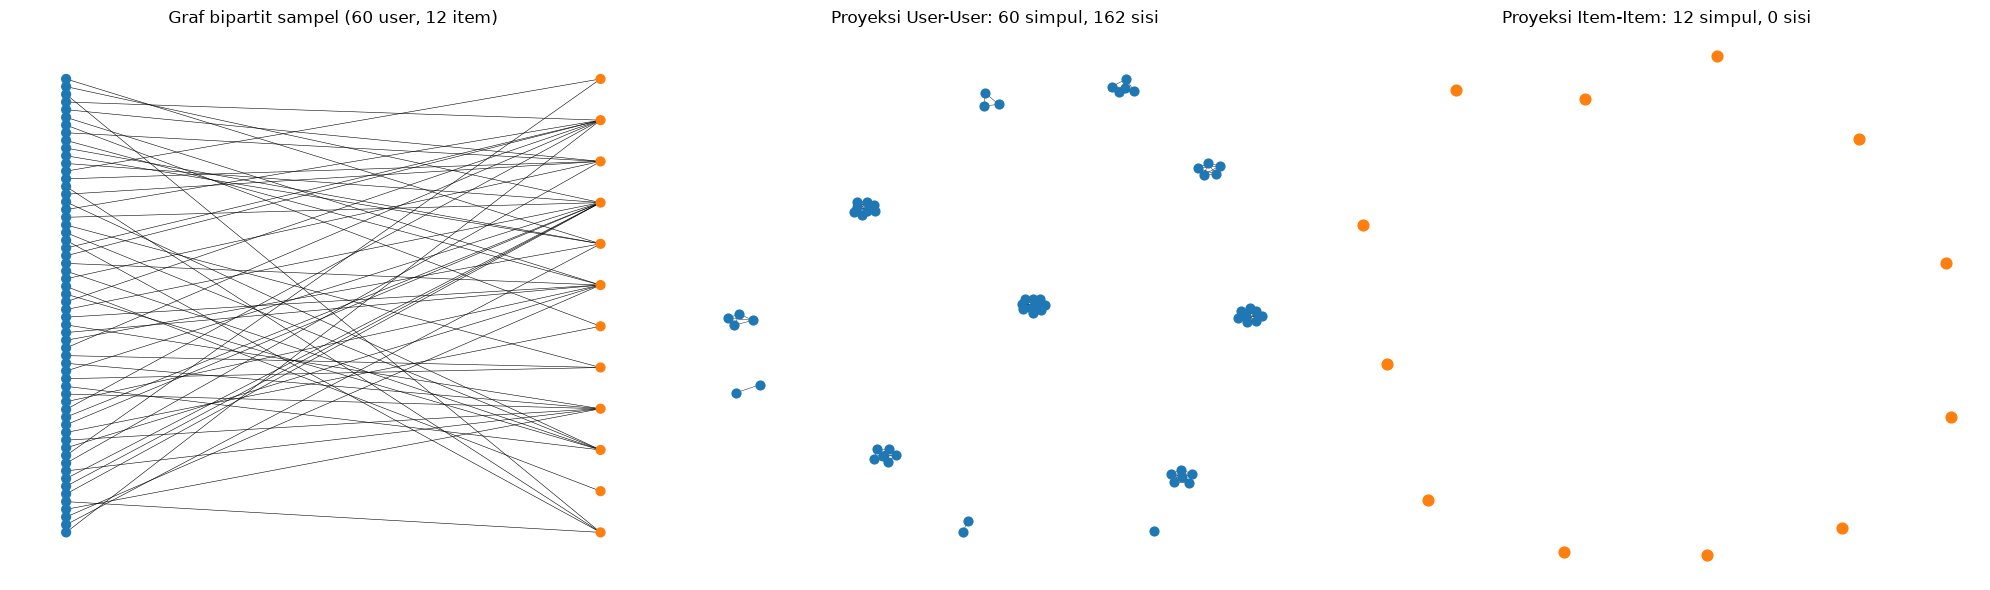

In [41]:
# Plot networkx pada sampel (graf penuh terlalu besar untuk digambar)
top_items = agg.groupby("item").size().nlargest(12).index
sub = agg[agg["item"].isin(top_items)].sample(n=60, random_state=SEED)

B = nx.Graph()
for r in sub.itertuples():
    B.add_node(f"U{r.visitor}", bipartite=0)
    B.add_node(f"I{r.item}", bipartite=1)
    B.add_edge(f"U{r.visitor}", f"I{r.item}", weight=r.w)

users_n = [n for n, d in B.nodes(data=True) if d["bipartite"] == 0]
items_n = [n for n, d in B.nodes(data=True) if d["bipartite"] == 1]
G_user = nx.bipartite.weighted_projected_graph(B, users_n)
G_item = nx.bipartite.weighted_projected_graph(B, items_n)

fig, ax = plt.subplots(1, 3, figsize=(20, 6))
pos = nx.bipartite_layout(B, users_n)
nx.draw(B, pos, ax=ax[0], node_size=40, width=0.4,
        node_color=["tab:blue" if n in users_n else "tab:orange" for n in B.nodes])
ax[0].set_title(f"Graf bipartit sampel ({len(users_n)} user, {len(items_n)} item)")
nx.draw(G_user, nx.spring_layout(G_user, seed=SEED), ax=ax[1], node_size=40, width=0.3, node_color="tab:blue")
ax[1].set_title(f"Proyeksi User-User: {G_user.number_of_nodes()} simpul, {G_user.number_of_edges()} sisi")
nx.draw(G_item, nx.spring_layout(G_item, seed=SEED), ax=ax[2], node_size=60, width=0.5, node_color="tab:orange")
ax[2].set_title(f"Proyeksi Item-Item: {G_item.number_of_nodes()} simpul, {G_item.number_of_edges()} sisi")
plt.tight_layout(); plt.show()

### No. 6: Proyeksi mana yang lebih baik

Ukuran yang dipakai: jumlah simpul dan batas atas jumlah sisi hasil proyeksi.
Pada proyeksi bipartit, sebuah simpul dengan derajat `d` membentuk `d(d-1)/2` pasangan simpul sisi lain.
Karena itu, jumlah sisi proyeksi User-User ditentukan oleh derajat Item, dan jumlah sisi proyeksi Item-Item ditentukan oleh derajat User.

In [42]:
user_deg = np.diff(X.indptr).astype(np.int64)                 # item per user
item_deg = np.diff(X.tocsc().indptr).astype(np.int64)         # user per item

edges_user_proj = int((item_deg * (item_deg - 1) // 2).sum())  # batas atas sisi User-User
edges_item_proj = int((user_deg * (user_deg - 1) // 2).sum())  # batas atas sisi Item-Item

cmp_df = pd.DataFrame({
    "simpul": [len(user_ids), len(item_ids)],
    "batas atas sisi": [edges_user_proj, edges_item_proj],
    "rata2 derajat (batas atas)": [2 * edges_user_proj / len(user_ids), 2 * edges_item_proj / len(item_ids)],
    "density VSM": [vsm_table.loc["density", "User"], vsm_table.loc["density", "Item"]],
}, index=["Proyeksi User-User", "Proyeksi Item-Item"])
display(cmp_df)

best_projection = "item" if edges_item_proj < edges_user_proj else "user"
print("Proyeksi yang lebih efisien menurut ukuran di atas:", best_projection)

,simpul,batas atas sisi,rata2 derajat (batas atas),density VSM
Proyeksi User-User,645108,21687675,67.237346,0.000009
Proyeksi Item-Item,168629,11232169,133.217525,0.000009


Proyeksi yang lebih efisien menurut ukuran di atas: item


**Tulis kesimpulan Anda di sel ini setelah melihat hasil di atas**, misalnya: proyeksi X dipilih karena jumlah simpul lebih sedikit, jumlah sisi lebih kecil, dan vektor lebih padat sehingga perhitungan similarity lebih murah.

### No. 7: Similarity pada graf terproyeksi

Similarity yang dipakai adalah cosine pada matriks biner (ada atau tidaknya interaksi).
Pada matriks biner, cosine antara dua simpul = `jumlah tetangga bersama / sqrt(derajat_a x derajat_b)`, sehingga bisa dihitung langsung dengan Cypher (7a) dan dicocokkan dengan hasil Python (7b).

In [43]:
# Gunakan periode yang sudah dibentuk pada langkah 2.1.
# P1 adalah data training; P2 hanya untuk evaluasi.
train_df = p1.copy()
test_df = p2.copy()

print("Train P1:", train_df.shape)
print("Test P2 :", test_df.shape)

Train P1: (1272928, 6)
Test P2 : (1238187, 6)


In [44]:
PROJECTION = best_projection     # ganti manual ke "item" atau "user" bila perlu
Bin = (X > 0).astype(np.float32).tocsr()

CFG = {
    "item": dict(label="Item", key="itemId", M=Bin.T.tocsr(), ids=item_ids),
    "user": dict(label="Visitor", key="visitorId", M=Bin, ids=user_ids),
}[PROJECTION]
LABEL, KEY, M_PROJ, IDS = CFG["label"], CFG["key"], CFG["M"], CFG["ids"]

# Record acuan: entitas dengan derajat peringkat ke-20 (deterministik, bisa direproduksi)
deg_proj = np.diff(M_PROJ.indptr)
REF_ID = int(IDS[np.argsort(-deg_proj)[19]])
print(f"Proyeksi: {PROJECTION} | acuan: {LABEL} {KEY}={REF_ID} | derajat: {deg_proj[np.argsort(-deg_proj)[19]]}")

TOP5_CYPHER = {
"item": f"""
MATCH (a:Item {{itemId: $ref}})<-[:{REL}]-(v:Visitor)
WITH a, collect(DISTINCT v) AS va
UNWIND va AS v
MATCH (v)-[:{REL}]->(b:Item) WHERE b <> a
WITH a, size(va) AS na, b, count(DISTINCT v) AS common
MATCH (b)<-[:{REL}]-(w:Visitor)
WITH na, b, common, count(DISTINCT w) AS nb
RETURN b.itemId AS id, common, toFloat(common) / sqrt(toFloat(na) * nb) AS score
ORDER BY score DESC LIMIT 5
""",
"user": f"""
MATCH (a:Visitor {{visitorId: $ref}})-[:{REL}]->(i:Item)
WITH a, collect(DISTINCT i) AS ia
UNWIND ia AS i
MATCH (i)<-[:{REL}]-(b:Visitor) WHERE b <> a
WITH a, size(ia) AS na, b, count(DISTINCT i) AS common
MATCH (b)-[:{REL}]->(j:Item)
WITH na, b, common, count(DISTINCT j) AS nb
RETURN b.visitorId AS id, common, toFloat(common) / sqrt(toFloat(na) * nb) AS score
ORDER BY score DESC LIMIT 5
""",
}[PROJECTION]

print(TOP5_CYPHER)
top5_cypher = pd.DataFrame(run_read(TOP5_CYPHER, ref=REF_ID))
display(top5_cypher)

Proyeksi: item | acuan: Item itemId=369447 | derajat: 394

MATCH (a:Item {itemId: $ref})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)
WITH a, collect(DISTINCT v) AS va
UNWIND va AS v
MATCH (v)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item) WHERE b <> a
WITH a, size(va) AS na, b, count(DISTINCT v) AS common
MATCH (b)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(w:Visitor)
WITH na, b, common, count(DISTINCT w) AS nb
RETURN b.itemId AS id, common, toFloat(common) / sqrt(toFloat(na) * nb) AS score
ORDER BY score DESC LIMIT 5



,id,common,score
0,274435,29,0.210877
1,356129,27,0.183415
2,257597,12,0.156094
3,379935,14,0.143971
4,187359,7,0.106329


**Penjelasan Cypher 7a.** Query mengumpulkan semua tetangga dari simpul acuan `a`, lalu mencari simpul lain `b` yang berbagi tetangga tersebut dan menghitung `common`.
Derajat `b` (`nb`) dihitung pada langkah berikutnya, kemudian skor cosine = `common / sqrt(na x nb)`. Hasil diurutkan menurun dan dibatasi 5 baris.

### No. 8 (bagian "sebelum"): kondisi graf sebelum nilai similarity ditulis

Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (s) { ... }', position=<SummaryInputPosition line=1, column=29, offset=28>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 28, 'line': 1, 'column': 29}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: 'MATCH ()-[s:SIMILAR_TO]->() CALL { WITH s DELETE s } IN TRANSACTIONS OF 10000 ROWS'


jumlah
objek  tipe                  
simpul Visitor         645108
       Item            168629
relasi VIEWED         1231426
       ADDED_TO_CART    31183
       BOUGHT           10319

Cypher (jalankan di Neo4j Browser untuk tangkapan layar):
 MATCH p=(v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item {itemId: $ref}) RETURN p LIMIT 15


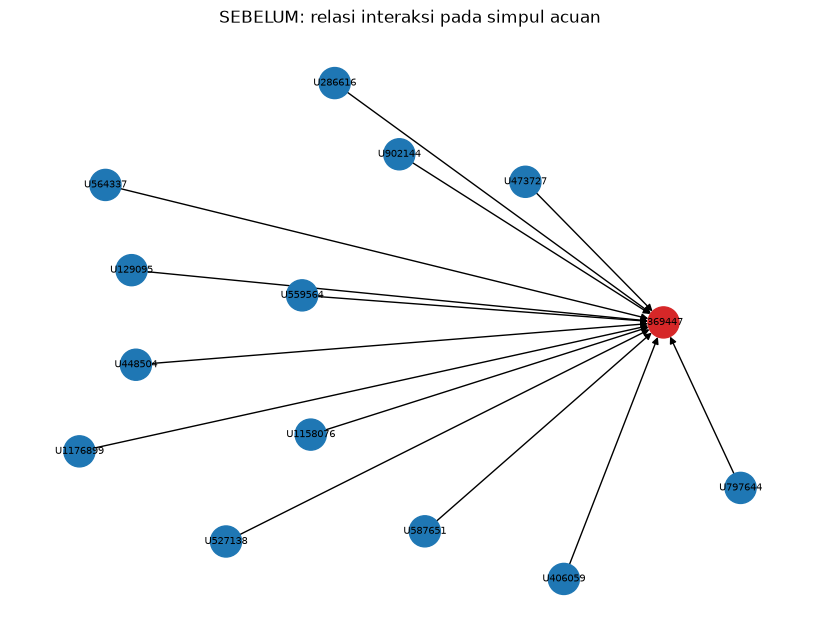

In [45]:
def snapshot():
    n = pd.DataFrame(run_read("MATCH (n) RETURN labels(n)[0] AS tipe, count(n) AS jumlah"))
    r = pd.DataFrame(run_read("MATCH ()-[r]->() RETURN type(r) AS tipe, count(r) AS jumlah"))
    return n.assign(objek="simpul"), r.assign(objek="relasi")

run_write("MATCH ()-[s:SIMILAR_TO]->() CALL { WITH s DELETE s } IN TRANSACTIONS OF 10000 ROWS")  # kondisi bersih

before = pd.concat(snapshot()).set_index(["objek", "tipe"])
display(before)

BEFORE_CYPHER = {
    "item": f"MATCH p=(v:Visitor)-[r:{REL}]->(i:Item {{itemId: $ref}}) RETURN p LIMIT 15",
    "user": f"MATCH p=(v:Visitor {{visitorId: $ref}})-[r:{REL}]->(i:Item) RETURN p LIMIT 15",
}[PROJECTION]
print("Cypher (jalankan di Neo4j Browser untuk tangkapan layar):\n", BEFORE_CYPHER)

def draw_star(edges, ref_label, title, edge_labels=False):
    G = nx.DiGraph()
    for a, b, lab in edges:
        G.add_edge(a, b, label=lab)
    pos = nx.spring_layout(G, seed=SEED)
    plt.figure(figsize=(8, 6))
    colors = ["tab:red" if n == ref_label else "tab:blue" for n in G.nodes]
    nx.draw(G, pos, with_labels=True, node_color=colors, node_size=500, font_size=7, arrows=True)
    if edge_labels:
        nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "label"), font_size=7)
    plt.title(title); plt.show()

raw = run_read(BEFORE_CYPHER.replace("RETURN p", "RETURN startNode(r).visitorId AS vid, endNode(r).itemId AS iid, type(r) AS rel"), ref=REF_ID)
edges_before = [(f"U{x['vid']}", f"I{x['iid']}", x["rel"]) for x in raw]
draw_star(edges_before, f"{'I' if PROJECTION=='item' else 'U'}{REF_ID}", "SEBELUM: relasi interaksi pada simpul acuan")

### No. 7b: Menuliskan nilai similarity kembali ke graf

Skor cosine untuk semua entitas yang memiliki derajat minimal `MIN_DEG`, dengan `K_SIM` tetangga terdekat per entitas, ditulis sebagai relasi `(:X)-[:SIMILAR_TO {score}]->(:X)`.

In [46]:
K_SIM = 10
MIN_DEG = 3

def topk_cosine(M, k=K_SIM, min_deg=MIN_DEG, block=500):
    deg = np.diff(M.indptr)
    keep = np.where(deg >= min_deg)[0]
    Mk = normalize(M[keep], norm="l2").tocsr().astype(np.float32)
    MkT = Mk.T.tocsr()
    out = []
    for start in tqdm(range(0, len(keep), block), desc="Menghitung cosine"):
        S = (Mk[start:start + block] @ MkT).tocsr()
        for r in range(S.shape[0]):
            lo, hi = S.indptr[r], S.indptr[r + 1]
            cols, vals = S.indices[lo:hi], S.data[lo:hi]
            m = cols != start + r
            cols, vals = cols[m], vals[m]
            if len(vals) == 0:
                continue
            if len(vals) > k:
                top = np.argpartition(-vals, k)[:k]
                cols, vals = cols[top], vals[top]
            for c, v in zip(cols, vals):
                out.append((keep[start + r], keep[c], float(v)))
    return out

pairs = topk_cosine(M_PROJ)
sim_rows = [{"a": int(IDS[a]), "b": int(IDS[b]), "score": round(s, 6)} for a, b, s in pairs]
print("Jumlah relasi SIMILAR_TO yang akan ditulis:", len(sim_rows))

WRITE_Q = f"""
UNWIND $batch AS row
MATCH (a:{LABEL} {{{KEY}: row.a}})
MATCH (b:{LABEL} {{{KEY}: row.b}})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.score, s.metric = 'cosine'
"""
for i in tqdm(range(0, len(sim_rows), 5000), desc="Menulis ke Neo4j"):
    run_write(WRITE_Q, batch=sim_rows[i:i + 5000])

VERIFY_Q = f"""
MATCH (a:{LABEL} {{{KEY}: $ref}})-[s:SIMILAR_TO]->(b:{LABEL})
RETURN b.{KEY} AS id, s.score AS score
ORDER BY score DESC LIMIT 5
"""
print(VERIFY_Q)
top5_graph = pd.DataFrame(run_read(VERIFY_Q, ref=REF_ID))
display(top5_graph)

cek = top5_cypher.merge(top5_graph, on="id", how="outer", suffixes=("_cypher", "_graf"))
display(cek)   

Menghitung cosine: 100%|██████████| 141/141 [00:04<00:00, 32.12it/s]


Jumlah relasi SIMILAR_TO yang akan ditulis: 414491


Menulis ke Neo4j: 100%|██████████| 83/83 [01:08<00:00,  1.21it/s]



MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN b.itemId AS id, s.score AS score
ORDER BY score DESC LIMIT 5



,id,score
0,274435,0.210877
1,356129,0.183415
2,257597,0.156094
3,379935,0.143971
4,187359,0.106329


,id,common,score_cypher,score_graf
0,187359,7,0.106329,0.106329
1,257597,12,0.156094,0.156094
2,274435,29,0.210877,0.210877
3,356129,27,0.183415,0.183415
4,379935,14,0.143971,0.143971


### No. 8 kondisi graf setelah similarity ditulis

jumlah_sebelum  jumlah_sesudah
objek  tipe                                         
relasi ADDED_TO_CART           31183           31183
       BOUGHT                  10319           10319
       SIMILAR_TO                  0          414491
       VIEWED                1231426         1231426
simpul Item                   168629          168629
       Visitor                645108          645108

Cypher (jalankan di Neo4j Browser untuk tangkapan layar):
 MATCH p=(a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item) RETURN p ORDER BY s.score DESC LIMIT 5


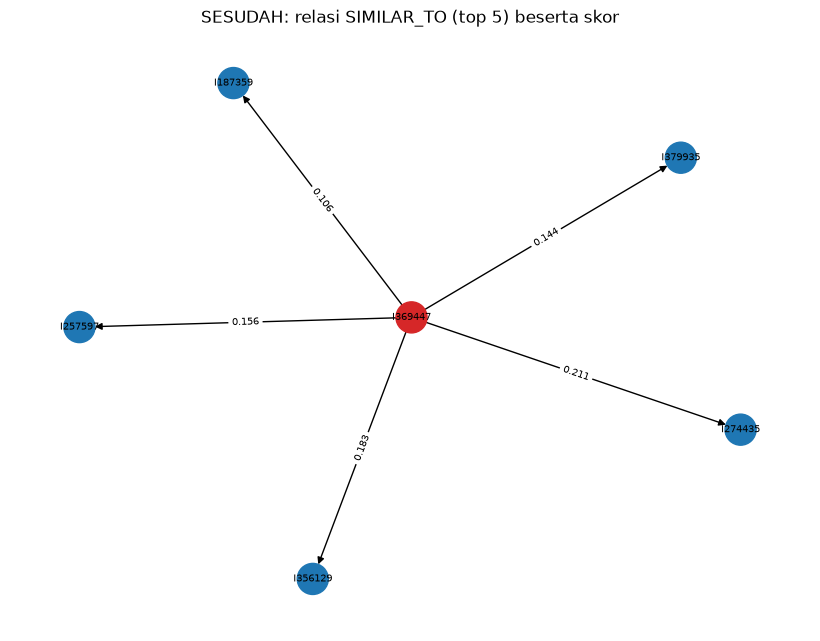

In [47]:
after = pd.concat(snapshot()).set_index(["objek", "tipe"])
display(before.join(after, lsuffix="_sebelum", rsuffix="_sesudah", how="outer").fillna(0).astype(int))

AFTER_CYPHER = f"MATCH p=(a:{LABEL} {{{KEY}: $ref}})-[s:SIMILAR_TO]->(b:{LABEL}) RETURN p ORDER BY s.score DESC LIMIT 5"
print("Cypher (jalankan di Neo4j Browser untuk tangkapan layar):\n", AFTER_CYPHER)

prefix = "I" if PROJECTION == "item" else "U"
edges_after = [(f"{prefix}{REF_ID}", f"{prefix}{r['id']}", f"{r['score']:.3f}") for r in top5_graph.to_dict("records")]
draw_star(edges_after, f"{prefix}{REF_ID}", "SESUDAH: relasi SIMILAR_TO (top 5) beserta skor", edge_labels=True)

## 2.2 Analytics: rekomendasi user-based KNN



### 2.2.1 Menyiapkan ground truth dan kandidat user

Ground truth menggunakan event `addtocart` dan `transaction` agar target evaluasi merepresentasikan minat yang lebih kuat daripada sekadar melihat item. Item baru yang tidak ada di katalog P1 dikeluarkan karena KNN dan baseline pada notebook ini hanya dapat merekomendasikan item yang dipelajari dari P1.

User kandidat harus memiliki minimal 3 item unik di P1, dan mempunyai minimal satu item ground truth yang belum pernah disentuh di P1. Seed 42 membuat pemilihan user dan sampel evaluasi dapat direproduksi.

In [ ]:
POSITIVE_EVENTS = {"addtocart", "transaction"}
K_NN = 5
N_RANK = 5
N_ADS = 3
SEED = 42
rng = np.random.default_rng(SEED)

pos_p2 = p2[
    p2["event"].isin(POSITIVE_EVENTS)
    & p2["itemid"].isin(item_index.index)
].copy()

gt_all = pos_p2.groupby("visitorid")["itemid"].apply(set).to_dict()

def seen_items(visitorid):
    """Item yang pernah disentuh user pada P1, berdasarkan matriks X."""
    if visitorid not in user_index.index:
        return set()
    user_pos = int(user_index.loc[visitorid])
    return set(item_ids[X[user_pos].indices])

def ground_truth(visitorid):
    """Item positif pada P2 yang belum pernah disentuh di P1."""
    return gt_all.get(visitorid, set()) - seen_items(visitorid)

candidates = []
for visitorid, relevant_items in gt_all.items():
    if visitorid not in user_index.index:
        continue
    user_pos = int(user_index.loc[visitorid])
    if user_deg[user_pos] >= 3 and (relevant_items - seen_items(visitorid)):
        candidates.append(visitorid)

candidates = sorted(candidates)
print("Event positif P2:", len(pos_p2))
print("User dengan ground truth P2:", len(gt_all))
print("Kandidat evaluasi:", len(candidates))
assert len(candidates) > 0, "Tidak ada kandidat. Periksa periode P1/P2, event, dan data yang dimuat."

Event positif P2: 38093
User dengan ground truth P2: 16657
Kandidat evaluasi: 418


### 2.2.2 Memilih satu user untuk soal 1a, 1b, dan 2

User dipilih secara acak dari kandidat yang memenuhi kriteria, dengan seed 42. Dengan demikian, hasil dapat direproduksi selama data dan urutan pemrosesan tidak berubah.

In [49]:
target = int(rng.choice(candidates))
t_pos = int(user_index.loc[target])
gt_target = ground_truth(target)

print("Seed:", SEED)
print("User target (visitorid):", target)
print("Jumlah item yang pernah disentuh pada P1:", len(seen_items(target)))
print("Ground truth baru pada P2:", sorted(gt_target))

Seed: 42
User target (visitorid): 175709
Jumlah item yang pernah disentuh pada P1: 4
Ground truth baru pada P2: [27736, 228083]


### 1a. Rekomendasi user-based KNN

Matriks `X` dari bagian 2.1 berisi bobot interaksi tiap user terhadap item. Kemiripan antar user dihitung dengan cosine similarity. Fungsi memeriksa maksimal 1.000 user paling mirip, lalu memilih hingga lima tetangga yang punya minimal dua item di P1 dan setidaknya satu item yang belum dilihat target. 

In [ ]:
Xn = normalize(X, norm="l2").tocsr()

popular_scores = np.asarray(X.sum(axis=0)).ravel()
popular_order = np.argsort(-popular_scores, kind="stable")

def knn_recommend(visitorid, k=K_NN, topn=N_RANK, pool=1000, min_items=2):
    """Menghasilkan (tetangga, rekomendasi KNN murni) untuk ID visitor asli."""
    empty_neighbors = pd.DataFrame(columns=["visitorid", "similarity"])
    empty_recs = pd.DataFrame(columns=["rank", "itemid", "score"])

    if visitorid not in user_index.index:
        return empty_neighbors, empty_recs

    u_pos = int(user_index.loc[visitorid])
    seen = seen_items(visitorid)

    # Cosine similarity 
    similarities = (Xn @ Xn[u_pos].T).toarray().ravel()
    similarities[u_pos] = 0.0

    positive_pos = np.flatnonzero(similarities > 0)
    positive_pos = positive_pos[np.argsort(similarities[positive_pos])[::-1]][:pool]

    selected_neighbors = []
    for j in positive_pos:
        neighbor_items = set(item_ids[X[j].indices])
        if user_deg[j] < min_items:
            continue
        if not (neighbor_items - seen):
            continue
        selected_neighbors.append(j)
        if len(selected_neighbors) == k:
            break

    neighbor_pos = np.asarray(selected_neighbors, dtype=int)

    if len(neighbor_pos):
        scores = np.asarray(X[neighbor_pos].T @ similarities[neighbor_pos]).ravel()
    else:
        scores = np.zeros(X.shape[1], dtype=float)

    for itemid in seen:
        if itemid in item_index.index:
            scores[int(item_index.loc[itemid])] = -np.inf

    eligible = np.flatnonzero(np.isfinite(scores) & (scores > 0))
    eligible = eligible[np.argsort(scores[eligible])[::-1]][:topn]

    neighbors_df = pd.DataFrame({
        "visitorid": user_ids[neighbor_pos],
        "similarity": similarities[neighbor_pos]
    })
    recs_df = pd.DataFrame({
        "rank": np.arange(1, len(eligible) + 1),
        "itemid": item_ids[eligible],
        "score": scores[eligible]
    })
    return neighbors_df, recs_df

neighbors, recs = knn_recommend(target, k=K_NN, topn=N_RANK)
print(f"Tetangga KNN yang berkontribusi (maksimal {K_NN}):")
display(neighbors)
print("Rekomendasi top-5 KNN murni:")
display(recs)

Tetangga KNN yang berkontribusi (maksimal 5):


,visitorid,similarity
0,196086,0.496942
1,814238,0.496139
2,500318,0.493939
3,297895,0.485071
4,750538,0.483494


Rekomendasi top-5 KNN murni:


,rank,itemid,score
0,1,294807,2.925631
1,2,256368,0.977433
2,3,358079,0.496942


### 1b. Tiga item yang diiklankan


In [51]:
ads = recs.head(N_ADS).copy()
display(ads)
print("Tiga item yang diiklankan:", ads["itemid"].tolist())

,rank,itemid,score
0,1,294807,2.925631
1,2,256368,0.977433
2,3,358079,0.496942


Tiga item yang diiklankan: [294807, 256368, 358079]


Tiga item yang diiklankan untuk user target diambil dari tiga peringkat teratas hasil KNN (k = 5), yaitu item 294807, 256368, dan 358079. Skor tiap item adalah jumlah bobot interaksi para tetangga terhadap item tersebut, dikali similarity tetangganya, sehingga item 294807 (skor 2,93) paling direkomendasikan, disusul 256368 (0,98) dan 358079 (0,50).

### 2. Baseline fallback populer dan metrik evaluasi

KNN murni hanya mengembalikan item yang memperoleh skor positif dari tetangga terpilih. Versi **KNN + fallback populer** melengkapi daftar tersebut jika jumlah rekomendasi kurang dari lima, dengan item berpopularitas tertinggi di P1 yang belum pernah disentuh user dan belum ada di daftar KNN.

Kedua metode menggunakan ground truth yang sama dan dievaluasi dengan:
- **Precision@5** = jumlah item relevan pada top-5 dibagi 5.
- **Recall@5** = jumlah item relevan pada top-5 dibagi jumlah item ground truth.
- **Hit@5** = 1 jika setidaknya satu item relevan muncul pada top-5, selain itu 0.
- **NDCG@5** memberi bobot lebih tinggi pada item relevan yang muncul lebih awal.

Item populer untuk fallback dihitung dari data P1 saja. Ground truth kosong dikeluarkan dari evaluasi.

In [ ]:
def hybrid_recommend(visitorid, k=K_NN, topn=N_RANK):
    """KNN dengan fallback item populer; kolom source menandai asal rekomendasi."""
    _, knn_df = knn_recommend(visitorid, k=k, topn=topn)
    results = [
        (int(row.itemid), float(row.score), "KNN")
        for row in knn_df.itertuples(index=False)
    ]
    used_items = {itemid for itemid, _, _ in results}
    seen = seen_items(visitorid)

    if len(results) < topn:
        for item_pos in popular_order:
            itemid = int(item_ids[item_pos])
            if itemid in seen or itemid in used_items:
                continue
            if popular_scores[item_pos] <= 0:
                continue
            results.append((itemid, 0.0, "populer"))
            used_items.add(itemid)
            if len(results) >= topn:
                break

    return pd.DataFrame(
        [(rank, itemid, score, source)
         for rank, (itemid, score, source) in enumerate(results[:topn], start=1)],
        columns=["rank", "itemid", "score", "source"]
    )

def metrics_at_k(recommendations, gt, k=5):
    recs_list = list(recommendations)[:k]
    rel = [1 if item in gt else 0 for item in recs_list]
    hits = sum(rel)
    precision = hits / k
    recall = hits / len(gt) if gt else 0.0
    hit = int(hits > 0)
    dcg = sum(r / math.log2(i + 2) for i, r in enumerate(rel))
    idcg = sum(1 / math.log2(i + 2) for i in range(min(len(gt), k)))
    ndcg = dcg / idcg if idcg else 0.0
    return {"Precision@5": precision, "Recall@5": recall, "Hit@5": hit, "NDCG@5": ndcg}

gt = gt_target
knn_ids = recs["itemid"].tolist()
hybrid_df = hybrid_recommend(target, k=K_NN, topn=N_RANK)
hybrid_ids = hybrid_df["itemid"].tolist()

print("Ground truth:", sorted(gt))
print("KNN murni:")
display(recs)
print("KNN + fallback populer:")
display(hybrid_df)

one_user_results = pd.DataFrame([
    {"Model": f"KNN murni (k={K_NN})", **metrics_at_k(knn_ids, gt)},
    {"Model": f"KNN + fallback populer (k={K_NN})", **metrics_at_k(hybrid_ids, gt)}
])
display(one_user_results)

Ground truth: [27736, 228083]
KNN murni:


,rank,itemid,score
0,1,294807,2.925631
1,2,256368,0.977433
2,3,358079,0.496942


KNN + fallback populer:


,rank,itemid,score,source
0,1,294807,2.925631,KNN
1,2,256368,0.977433,KNN
2,3,358079,0.496942,KNN
3,4,309778,0.000000,populer
4,5,5411,0.000000,populer


,Model,Precision@5,Recall@5,Hit@5,NDCG@5
0,KNN murni (k=5),0.0,0.0,0,0.0
1,KNN + fallback populer (k=5),0.0,0.0,0,0.0


### 2.2.3 Evaluasi 100 user acak: KNN murni dibandingkan KNN + fallback populer

Hasil satu user sangat dipengaruhi oleh jumlah interaksi dan item yang muncul pada P2. Karena itu, kedua metode dievaluasi pada sampel yang sama, maksimal 100 user kandidat, dipilih tanpa pengembalian dengan seed 42. KNN murni tidak mengisi kekurangan rekomendasi; versi hybrid mengisi kekurangan tersebut dengan item populer dari P1. Dengan demikian, perbedaan metrik menunjukkan dampak fallback populer.

Precision@5         Recall@5         Hit@5  \
                                    mean     std     mean     std  mean   
Model                                                                     
KNN + fallback populer (k=5)       0.006  0.0343   0.0127  0.1028  0.03   
KNN murni (k=5)                    0.006  0.0343   0.0127  0.1028  0.03   

                                     NDCG@5          
                                 std   mean     std  
Model                                                
KNN + fallback populer (k=5)  0.1714  0.007  0.0443  
KNN murni (k=5)               0.1714  0.007  0.0443

Jumlah user dievaluasi: 100
KNN murni menang berdasarkan Hit@5: 0
KNN + fallback populer menang berdasarkan Hit@5: 0
Seri berdasarkan Hit@5: 100


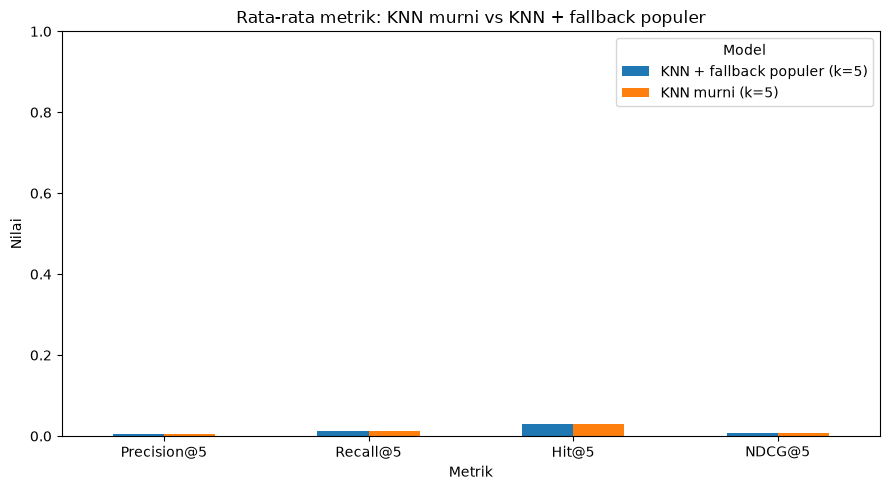

In [53]:
sample_size = min(100, len(candidates))
sample_users = rng.choice(candidates, size=sample_size, replace=False)

evaluation_rows = []
for visitorid in sample_users:
    visitorid = int(visitorid)
    gt_u = ground_truth(visitorid)
    if not gt_u:
        continue

    _, knn_df = knn_recommend(visitorid, k=K_NN, topn=N_RANK)
    hybrid_df = hybrid_recommend(visitorid, k=K_NN, topn=N_RANK)

    for model_name, rec_df in [
        (f"KNN murni (k={K_NN})", knn_df),
        (f"KNN + fallback populer (k={K_NN})", hybrid_df)
    ]:
        metrics = metrics_at_k(rec_df["itemid"].tolist(), gt_u, k=N_RANK)
        evaluation_rows.append({"visitorid": visitorid, "Model": model_name, **metrics})

per_user_results = pd.DataFrame(evaluation_rows)
if per_user_results.empty:
    print("Evaluasi tidak menghasilkan user dengan ground truth yang valid.")
else:
    metric_cols = ["Precision@5", "Recall@5", "Hit@5", "NDCG@5"]
    summary = per_user_results.groupby("Model")[metric_cols].agg(["mean", "std"])
    display(summary.round(4))

    pivot_hit = per_user_results.pivot(index="visitorid", columns="Model", values="Hit@5").dropna()
    knn_name = f"KNN murni (k={K_NN})"
    hybrid_name = f"KNN + fallback populer (k={K_NN})"
    knn_wins = int((pivot_hit[knn_name] > pivot_hit[hybrid_name]).sum())
    hybrid_wins = int((pivot_hit[knn_name] < pivot_hit[hybrid_name]).sum())
    ties = int((pivot_hit[knn_name] == pivot_hit[hybrid_name]).sum())
    print(f"Jumlah user dievaluasi: {len(pivot_hit)}")
    print(f"KNN murni menang berdasarkan Hit@5: {knn_wins}")
    print(f"KNN + fallback populer menang berdasarkan Hit@5: {hybrid_wins}")
    print(f"Seri berdasarkan Hit@5: {ties}")

    means = per_user_results.groupby("Model")[metric_cols].mean()
    ax = means.T.plot(kind="bar", figsize=(9, 5))
    ax.set_title("Rata-rata metrik: KNN murni vs KNN + fallback populer")
    ax.set_ylabel("Nilai")
    ax.set_xlabel("Metrik")
    ax.set_ylim(0, 1)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

**Penjelasan evaluasi.** Kode mengambil sampel 100 user kandidat secara acak (seed 42, tanpa pengembalian). Untuk tiap user, kode membuat top-5 rekomendasi dari dua model, yaitu KNN murni dan KNN + fallback populer, lalu membandingkannya dengan ground truth P2 memakai Precision@5, Recall@5, Hit@5, dan NDCG@5. Hasilnya dirata-rata per model, dan jumlah "kemenangan" dihitung dari Hit@5 per user.

**Hasil.** Kedua model menghasilkan nilai identik: Hit@5 = 0,03, Precision@5 = 0,006, Recall@5 = 0,0127, dan NDCG@5 = 0,007. Hanya 3 dari 100 user yang item ground truth-nya muncul di top-5, dan seluruh 100 user berakhir seri. Nilai yang rendah wajar karena VSM sangat sparse (rata-rata user hanya menyentuh sedikit item) dan ground truth hanya mencakup item baru yang di-*addtocart*/dibeli di P2. 

**Interpretasi.** Fallback populer tidak mengubah hasil pada sampel ini, sehingga belum ada bukti bahwa fallback memperbaiki KNN. 

### 2.2.4 Sensitivitas jumlah tetangga (k)

Soal utama menggunakan `k = 5`. Sebagai analisis tambahan, bandingkan `k = 3, 5, 10, 20` pada sampel user yang sama. Bagian ini tidak mengganti nilai utama soal, hanya memeriksa apakah hasil berubah saat jumlah tetangga berubah.

In [54]:
sensitivity_rows = []
for k_value in [3, 5, 10, 20]:
    for visitorid in sample_users:
        visitorid = int(visitorid)
        gt_u = ground_truth(visitorid)
        if not gt_u:
            continue
        _, rec_df = knn_recommend(visitorid, k=k_value, topn=N_RANK)
        sensitivity_rows.append({
            "k": k_value,
            **metrics_at_k(rec_df["itemid"].tolist(), gt_u, k=N_RANK)
        })

sensitivity = pd.DataFrame(sensitivity_rows)
if not sensitivity.empty:
    sensitivity_summary = sensitivity.groupby("k").agg(["mean", "std"])
    display(sensitivity_summary.round(4))

Precision@5         Recall@5         Hit@5          NDCG@5        
          mean     std     mean     std  mean     std    mean     std
k                                                                    
3        0.008  0.0394   0.0127  0.1028  0.04  0.1969  0.0109  0.0568
5        0.006  0.0343   0.0127  0.1028  0.03  0.1714  0.0070  0.0443
10       0.006  0.0343   0.0225  0.1426  0.03  0.1714  0.0130  0.0816
20       0.006  0.0343   0.0225  0.1426  0.03  0.1714  0.0106  0.0634

Analisis sensitivitas membandingkan k = 3, 5, 10, dan 20 pada 100 user sampel yang sama. Nilai metrik berubah sangat kecil: Hit@5 berkisar 0,03-0,04, Precision@5 0,006-0,008, Recall@5 0,013-0,023, dan NDCG@5 0,007-0,013. k = 3 sedikit unggul pada Hit@5 (0,04), sedangkan k = 10 unggul pada Recall@5 (0,0225) dan NDCG@5 (0,013). Selisih ini hanya setara dengan satu atau dua user dari 100 dan simpangan bakunya jauh lebih besar dari rata-ratanya, sehingga tidak cukup kuat untuk menyatakan satu nilai k lebih baik. Kesimpulannya, kualitas rekomendasi tidak sensitif terhadap k karena bottleneck-nya ada pada sparsity data, bukan pada jumlah tetangga, dan k = 5 tetap dipakai sebagai nilai utama sesuai soal.